---
title: "L4-04 · Backdoor adjustment"
short_title: "Backdoor adjustment"
subtitle: "If a measured set blocks every noncausal path into the treatment without touching its descendants, then reweighting stratum risks to one common covariate mix turns an observed contrast into a causal effect."
description: "Decide whether a set of measured variables satisfies the backdoor criterion and use it to compute an intervention effect by standardization or by inverse probability weighting."
tags: [level-4, coursebook]
---

(lesson-l4-04)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 110 minutes  
**Big idea.** If a measured set blocks every noncausal path into the treatment without touching its descendants, then reweighting stratum risks to one common covariate mix turns an observed contrast into a causal effect.  
**Before this lesson.** [L4-02](#lesson-l4-02), [L4-03](#lesson-l4-03), [L3-07](#lesson-l3-07)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Check the backdoor criterion for a candidate set by listing every backdoor path, applying the d-separation blocking rule to each, and excluding descendants of the treatment.
- Derive the adjustment formula $P(y \mid do(x)) = \sum_z P(y \mid x, z)P(z)$ from the truncated factorization and compute standardized risks and their difference.
- Compute an inverse probability weighted estimate, prove that it equals standardization in the population, and state the positivity condition both need.
- Simulate a confounded model and compare the naive, standardized, and weighted estimates with the true effect.

## Why this matters

Here is a puzzle. In a model population, a treatment raises the risk of an outcome by $0.1$ among people with $Z = 0$ and by $0.2$ among people with $Z = 1$. Yet the treated group's risk is $0.68$ and the untreated group's risk is $0.20$, a difference of $0.48$. How can the overall difference be more than twice as large as the effect in either group? The answer is that $Z$ does two jobs at once: it makes treatment more likely and it raises the risk. Comparing treated and untreated people mixes the effect of $X$ with the effect of being the kind of person who gets $X$.

This lesson answers two questions that every observational study faces. When can the effect of an intervention, $P(y \mid do(x))$, be computed from data where nobody was assigned anything? And how? The backdoor criterion gives a purely graphical test for the first question [@pearl]. Standardization and inverse probability weighting give two computations of the same answer [@hernan]. Both are only as good as the causal graph, which is why the test comes before the arithmetic.

:::{dropdown} Key terms

**Intervention $do(X = x)$**
: Setting $X$ to $x$ by an outside action, which replaces the mechanism that normally produces $X$ and leaves every other mechanism unchanged.

**Backdoor path**
: A path between treatment $X$ and outcome $Y$ whose first edge points into $X$, such as $X \leftarrow Z \rightarrow Y$.

**Backdoor criterion**
: A set $Z$ satisfies it when no member of $Z$ is a descendant of $X$ and $Z$ blocks every backdoor path from $X$ to $Y$.

**Standardization**
: Averaging stratum risks $P(y \mid x, z)$ over one common distribution $P(z)$ for every treatment value.

**Propensity score**
: The treatment probability $e(z) = P(X = 1 \mid Z = z)$ in the stratum $Z = z$.

**Inverse probability weighting (IPW)**
: Weighting each unit by $1/P(X = x \mid Z = z)$ for the treatment it received, which builds a pseudo-population where $X$ is independent of $Z$.

**Positivity**
: Every stratum that occurs in the target population has a nonzero probability of each treatment value being compared.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_04 as _lessonfigs

## Seeing versus doing

Take the smallest confounded model. A binary covariate $Z$ has $P(Z = 1) = 0.5$. It raises the chance of treatment, $P(X = 1 \mid Z = 0) = 0.2$ and $P(X = 1 \mid Z = 1) = 0.8$, and it raises the risk of the outcome. The stratum risks $P(Y = 1 \mid X = x, Z = z)$ are $0.2$ and $0.8$ for treated people with $Z = 0$ and $Z = 1$, and $0.1$ and $0.6$ for untreated people. This is not the course engine's additive model of [L4-01](#lesson-l4-01): here the treatment adds $0.1$ to the risk when $Z = 0$ and $0.2$ when $Z = 1$. The graph is below; $X$, $Y$ and $Z$ are all measured.

```{mermaid}
graph LR
  Z[Z covariate] --> X[X treatment]
  Z --> Y[Y outcome]
  X --> Y
```

*The running example. $Z$ opens the backdoor path $X \leftarrow Z \rightarrow Y$, so the observed association between $X$ and $Y$ mixes the causal arrow with the common cause.*

:::{prf:definition} Intervention and the truncated factorization
:label: def-l4-04-truncated
Let a causal DAG on variables $V_1, \dots, V_k$ have the Markov factorization $P(v) = \prod_i P(v_i \mid pa_i)$, where $pa_i$ are the values of the parents of $V_i$ (see [L4-01](#lesson-l4-01) and [L4-02](#lesson-l4-02)). The intervention $do(X = x)$ removes the mechanism of $X$ and holds $X$ at $x$; every other mechanism is unchanged. The interventional distribution is the product of the remaining factors, [](#eq-l4-04-truncated), for every $v$ that agrees with $X = x$, and $0$ otherwise. [L4-07](#lesson-l4-07) studies this rule and its limits in detail.
:::

$$
P(v \mid do(X = x)) = \prod_{i:\, V_i \neq X} P(v_i \mid pa_i)\,\Big|_{X = x}
$$ (eq-l4-04-truncated)

:::{prf:theorem} Adjustment for the parents of the treatment
:label: thm-l4-04-parents
In a causal DAG whose variables are all measured, let $T$ be the set of parents of $X$. For every $t$ with $P(t) > 0$ assume $P(x \mid t) > 0$. Then $P(y \mid do(x)) = \sum_t P(y \mid x, t)\, P(t)$. This restates Corollary [](#cor-l4-01-parents) of [L4-01](#lesson-l4-01); the proof below reaches it by a slightly different route.
:::

:::{prf:proof}
Write $W$ for all variables other than $X$, $T$ and $Y$. Compare the observational factorization with [](#eq-l4-04-truncated): the only difference is the missing factor $P(x \mid t)$, so for every $(t, y, w)$, $P(t, y, w \mid do(x)) = P(x, t, y, w)/P(x \mid t)$. By the chain rule, $P(x, t, y, w) = P(t)\,P(x \mid t)\,P(y, w \mid x, t)$. Dividing, $P(t, y, w \mid do(x)) = P(t)\,P(y, w \mid x, t)$. Summing over $w$ and $t$ gives $P(y \mid do(x)) = \sum_t P(t)\, P(y \mid x, t)$. Positivity makes every conditional probability in the formula well defined.
:::

In the running example $Z$ is the only parent of $X$, so $P(Y = 1 \mid do(X = 1)) = 0.5(0.2) + 0.5(0.8) = 0.50$ and $P(Y = 1 \mid do(X = 0)) = 0.5(0.1) + 0.5(0.6) = 0.35$. The causal risk difference is $0.50 - 0.35 = 0.15$, the average of the two stratum effects $0.1$ and $0.2$. The naive contrast of $0.48$ overstates it more than threefold.

## The backdoor criterion

The parents of $X$ are often unmeasured, or there are better sets to use. We need a test that says which sets of measured variables do the same job. The idea: the association between $X$ and $Y$ travels along every path between them. Directed paths out of $X$ carry the effect we want. Paths that enter $X$ through an incoming arrow, the **backdoor paths**, carry spurious association. A good adjustment set closes all backdoor paths and leaves the directed paths alone.

:::{prf:definition} Backdoor criterion
:label: def-l4-04-backdoor
A set $Z$ of variables satisfies the **backdoor criterion** relative to an ordered pair $(X, Y)$ in a DAG if (i) no node in $Z$ is a descendant of $X$, and (ii) $Z$ blocks every path between $X$ and $Y$ that contains an arrow into $X$. A path is **blocked** by $Z$ when it contains a noncollider that is in $Z$, or a collider such that neither it nor any of its descendants is in $Z$ (the d-separation rule of [L4-02](#lesson-l4-02)) [@pearlcausality].
:::

:::{figure} ../../_static/animations/l4_04_backdoor_paths.mp4
:alt: A six-node causal graph. The directed path from X through W to Y is highlighted in blue, the four backdoor paths are highlighted one at a time and listed, then three candidate sets are tested and each path is marked open or blocked.
:width: 100%

The backdoor criterion is checked path by path. Conditioning on $Z_3$ alone closes three paths but opens the fourth through the collider $Z_3$; the set $\{Z_1, Z_3\}$ closes all four.
:::

:::{dropdown} What the animation shows
The graph has arrows $Z_1 \to X$, $Z_1 \to Z_3$, $Z_2 \to Z_3$, $Z_2 \to Y$, $Z_3 \to X$, $Z_3 \to Y$, $X \to W$ and $W \to Y$. The directed path $X \to W \to Y$ is highlighted in blue as the path to keep open. The four backdoor paths are highlighted and listed: $X \leftarrow Z_3 \rightarrow Y$, $X \leftarrow Z_1 \rightarrow Z_3 \rightarrow Y$, $X \leftarrow Z_3 \leftarrow Z_2 \rightarrow Y$ and $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$. With the empty set the first three are open and the fourth is blocked by the collider $Z_3$. With $\{Z_3\}$ the first three become blocked, but the fourth is opened because its collider is now conditioned on. With $\{Z_1, Z_3\}$ all four are blocked, so the set is valid. Finally $W$ is flagged: it is a descendant of $X$ and must never be in an adjustment set for the total effect.
:::

```{mermaid}
graph TD
  Z1 --> X
  Z1 --> Z3
  Z2 --> Z3
  Z2 --> Y
  Z3 --> X
  Z3 --> Y
  X --> W
  W --> Y
```

*The same six-node graph as a static reference. $Z_3$ is a confounder on some paths and a collider on the path through $Z_1$ and $Z_2$.*

Work through the graph by hand. There are exactly four backdoor paths: $X \leftarrow Z_3 \rightarrow Y$, $X \leftarrow Z_1 \rightarrow Z_3 \rightarrow Y$, $X \leftarrow Z_3 \leftarrow Z_2 \rightarrow Y$, and $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$. On the last one $Z_3$ is a collider. The empty set leaves three paths open. The set $\{Z_3\}$ blocks the first three, because $Z_3$ is a noncollider on each, but it opens the fourth. Adding either $Z_1$ or $Z_2$ closes that path again, so $\{Z_1, Z_3\}$, $\{Z_2, Z_3\}$ and $\{Z_1, Z_2, Z_3\}$ are valid. Any set that contains $W$ fails condition (i).

:::{prf:theorem} Backdoor adjustment
:label: thm-l4-04-backdoor
If $Z$ satisfies the backdoor criterion relative to $(X, Y)$, and $P(x, z) > 0$ for every $z$ with $P(z) > 0$, then the causal effect of $X$ on $Y$ is identified and [](#eq-l4-04-adjust) holds [@pearlcausality; @pearl].
:::

$$
P(y \mid do(x)) = \sum_z P(y \mid x, z)\, P(z)
$$ (eq-l4-04-adjust)

:::{prf:proof}
*Proof sketch.* Condition on $Z$ inside the interventional distribution: $P(y \mid do(x)) = \sum_z P(y \mid do(x), z)\, P(z \mid do(x))$. Two facts finish the argument.

(a) $P(z \mid do(x)) = P(z)$. The non-descendants of $X$ form a set that contains the parents of each of its members (a parent of a non-descendant cannot be $X$ or a descendant of $X$). In [](#eq-l4-04-truncated), sum out the descendants of $X$ from the last one in a topological order back to the first: each factor sums to 1, leaving the product of the factors of the non-descendants. Summing $X$ and its descendants out of the observational factorization leaves the same product. So the joint distribution of the non-descendants, and of $Z$ by condition (i), is the same with and without the intervention.

(b) $P(y \mid do(x), z) = P(y \mid x, z)$. Delete the arrows out of $X$. By condition (ii), $Z$ d-separates $X$ from $Y$ in that graph, so given $Z$ the only association left between $X$ and $Y$ in the original graph flows along directed paths out of $X$, which the intervention leaves intact. Turning this sentence into a formal proof is exactly rule 2 of the do-calculus, which [L4-07](#lesson-l4-07) introduces; see [@pearlcausality], Section 3.3.

Substituting (a) and (b) gives [](#eq-l4-04-adjust). When $Z$ is the parent set of $X$, [](#thm-l4-04-parents) proves the same result without the do-calculus.
:::

Enumerate the backdoor paths of the six-node graph, test every candidate set with the blocking rule, and cross-check against `networkx`: the criterion is equivalent to 'no descendants of $X$, and $Z$ d-separates $X$ and $Y$ once the arrows out of $X$ are deleted'.


In [2]:
import itertools
import networkx as nx

# A six-node example: Z1, Z2 are background causes, Z3 a confounder, W a mediator
G = nx.DiGraph([("Z1", "X"), ("Z1", "Z3"), ("Z2", "Z3"), ("Z2", "Y"),
                ("Z3", "X"), ("Z3", "Y"), ("X", "W"), ("W", "Y")])

def backdoor_paths(G, x, y):
    """Paths between x and y (ignoring direction) whose first edge points INTO x."""
    for p in nx.all_simple_paths(G.to_undirected(), x, y):
        if G.has_edge(p[1], p[0]):
            yield p

def blocked(G, path, S):
    """d-separation rule for one path: a conditioned noncollider, or an unconditioned collider."""
    for a, v, b in zip(path, path[1:], path[2:]):
        if G.has_edge(a, v) and G.has_edge(b, v):          # v is a collider on this path
            if v not in S and not (nx.descendants(G, v) & S):
                return True
        elif v in S:
            return True
    return False

def backdoor_ok(G, x, y, S):
    if S & nx.descendants(G, x):                            # condition (i): no descendants of X
        return False
    return all(blocked(G, p, S) for p in backdoor_paths(G, x, y))   # condition (ii)

for p in backdoor_paths(G, "X", "Y"):
    print("backdoor path:", " - ".join(p))

# cross-check with networkx: delete the arrows OUT of X, then ask for d-separation
G_cut = G.copy()
G_cut.remove_edges_from(list(G.out_edges("X")))
valid = []
for k in range(5):
    for S in itertools.combinations(["Z1", "Z2", "Z3", "W"], k):
        S = set(S)
        ok = backdoor_ok(G, "X", "Y", S)
        assert ok == (not (S & nx.descendants(G, "X")) and nx.is_d_separator(G_cut, {"X"}, {"Y"}, S))
        if ok:
            valid.append(sorted(S))
print("valid backdoor sets:", valid)

backdoor path: X - Z1 - Z3 - Y
backdoor path: X - Z1 - Z3 - Z2 - Y
backdoor path: X - Z3 - Y
backdoor path: X - Z3 - Z2 - Y
valid backdoor sets: [['Z1', 'Z3'], ['Z2', 'Z3'], ['Z1', 'Z2', 'Z3']]


:::{warning} More adjustment is not always better
$\{Z_3\}$ is a natural guess, since $Z_3$ is a common cause of $X$ and $Y$, and it is wrong: it opens the collider path. Adjusting for the mediator $W$ is also wrong: it blocks the effect we are trying to measure. Adjustment sets are chosen from the graph, never by including every measured variable.
:::

## Standardization: one covariate mix for both arms

Why does the naive contrast fail, and what exactly does adjustment change? By the law of total probability ([L3-07](#lesson-l3-07)), the observed risk in arm $x$ is a weighted average of stratum risks with the arm's own covariate mix $P(z \mid x)$. The adjusted risk uses the same stratum risks with the population mix $P(z)$. Equation [](#eq-l4-04-two-averages) shows the two side by side: the only change is the weights.

$$
P(Y = 1 \mid X = x) = \sum_z P(Y = 1 \mid x, z)\, P(z \mid x) \qquad\text{versus}\qquad P(Y = 1 \mid do(X = x)) = \sum_z P(Y = 1 \mid x, z)\, P(z)
$$ (eq-l4-04-two-averages)

:::{figure} ../../_static/animations/l4_04_standardize.mp4
:alt: Two panels of rectangles, one for the treated and one for the untreated arm. Each rectangle's width is a stratum weight and its height a stratum risk; the widths slide to equal halves and the total areas change from 0.68 and 0.20 to 0.50 and 0.35.
:width: 100%

Width is the stratum weight, height the stratum risk, area the average risk. Moving both arms to the population mix $P(Z) = (0.5, 0.5)$ turns the observed contrast $0.48$ into the causal $0.15$.
:::

:::{dropdown} What the animation shows
Each arm is drawn as two adjacent rectangles, one per stratum of $Z$. The heights are the stratum risks: $0.2$ and $0.8$ for the treated arm, $0.1$ and $0.6$ for the untreated arm. At first the widths are the arms' own covariate mixes: the treated arm is $0.20$ of $Z = 0$ and $0.80$ of $Z = 1$, the untreated arm $0.80$ and $0.20$. The total areas, shown live, are the observed risks $0.68$ and $0.20$, a contrast of $0.48$. The widths then slide to the population mix $0.50$ and $0.50$ for both arms. The heights never change. The areas become $0.50$ and $0.35$, and the contrast becomes $0.50 - 0.35 = 0.15$.
:::

Bayes' rule gives the arm mixes: $P(Z = 1 \mid X = 1) = 0.8 \cdot 0.5/0.5 = 0.8$ and $P(Z = 1 \mid X = 0) = 0.2$. So the observed risks are $0.2(0.2) + 0.8(0.8) = 0.68$ and $0.8(0.1) + 0.2(0.6) = 0.20$, while the standardized risks are $0.50$ and $0.35$. The treated arm is crowded into the high-risk stratum, and the naive comparison credits the treatment with that crowding. Treatment-specific weights would keep the crowding; one common weight removes it.


In [3]:
_show(_lessonfigs.confounding_explorer())

**Explore.** Change the confounding strength $c$, where $P(X = 1 \mid Z = 0) = 0.5 - c$ and $P(X = 1 \mid Z = 1) = 0.5 + c$. (This $c$ moves the treatment probabilities; it is a different parameter from the $c$ of [L4-01](#lesson-l4-01), which moved the outcome risk.) Observed risks move; standardized risks do not.

:::{dropdown} What the figure shows
The first panel shows the observed and standardized risks of $Y = 1$ for each arm. The second panel plots the naive contrast against $c$, a straight line from $0.15$ at $c = 0$ to about $0.64$ at $c = 0.45$, and the adjusted contrast, a flat line at the true $0.15$. At $c = 0$ treatment does not depend on $Z$ and the two agree. At $c = 0.3$, the lesson's value, the observed risks are $0.68$ and $0.20$ and the standardized ones $0.50$ and $0.35$.
:::

## Inverse probability weighting

Standardization fixes the weights of the strata. Inverse probability weighting fixes the people instead: it up-weights units whose treatment was unusual for their stratum, so that every stratum ends up with the same treatment mix.

:::{prf:proposition} IPW equals standardization
:label: prop-l4-04-ipw
Assume positivity, $0 < P(X = x \mid Z = z)$ whenever $P(z) > 0$. Then $\mathbb{E}\left[\dfrac{\mathbf{1}\{X = x\}\, Y}{P(X = x \mid Z)}\right] = \sum_z \mathbb{E}[Y \mid X = x, Z = z]\, P(z)$. If $Z$ satisfies the backdoor criterion, the left side is therefore $\mathbb{E}[Y \mid do(X = x)]$.
:::

:::{prf:proof}
Condition on $Z$ and then on $X$: $\mathbb{E}\big[\mathbf{1}\{X = x\} Y / P(X = x \mid Z)\big] = \sum_z P(z) \cdot \dfrac{P(X = x \mid z)\, \mathbb{E}[Y \mid x, z]}{P(X = x \mid z)} = \sum_z P(z)\, \mathbb{E}[Y \mid x, z]$. The indicator keeps only units with $X = x$, which occur with probability $P(X = x \mid z)$ in stratum $z$; the weight cancels that probability. The last statement is [](#thm-l4-04-backdoor).
:::

:::{figure} ../../_static/animations/l4_04_ipw_pseudo.mp4
:alt: A two by two grid of squares, rows X equal 1 and 0, columns Z equal 0 and 1, with counts 100, 400, 400, 100. Weights 5, 1.25, 1.25, 5 grow every square to 500.
:width: 100%

In a population of 1000, weighting by $1/P(X = x \mid Z = z)$ grows every cell to 500. In the pseudo-population treatment no longer depends on $Z$, and the plain contrast is $0.15$.
:::

:::{dropdown} What the animation shows
A grid shows the 1000 people of the running example by treatment and covariate: 100 treated and 400 untreated with $Z = 0$, 400 treated and 100 untreated with $Z = 1$. Each square is shaded red in proportion to its risk of $Y = 1$. The weights are $1/P(X = x \mid Z = z)$: $100 \times 5 = 500$, $400 \times 1.25 = 500$, $400 \times 1.25 = 500$ and $100 \times 5 = 500$. The squares grow until every cell holds 500, so $X$ is independent of $Z$ in the pseudo-population. The treated risk is $(500 \cdot 0.2 + 500 \cdot 0.8)/1000 = 0.50$, the untreated risk is $(500 \cdot 0.1 + 500 \cdot 0.6)/1000 = 0.35$, and the difference is $0.15$.
:::


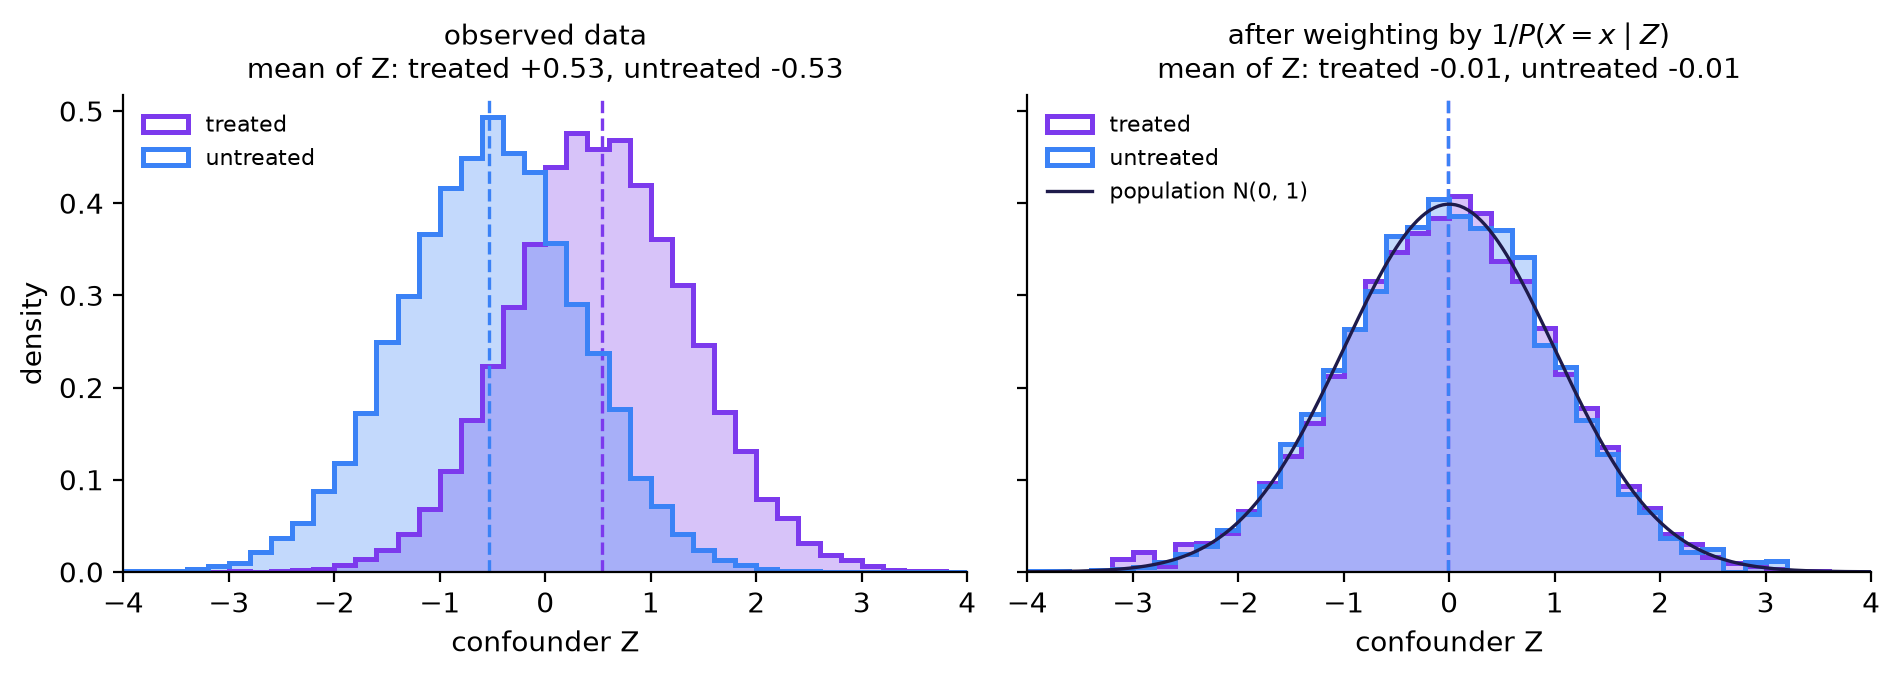

In [4]:
_show_mpl(_lessonfigs.balance_before_after())

*A continuous confounder $Z \sim N(0, 1)$ with propensity $P(X = 1 \mid Z) = 1/(1 + e^{-1.5 Z})$, 40,000 simulated units. Left: the treated arm sits to the right of the untreated arm. Right: after weighting by $1/P(X = x \mid Z)$, both arms have the population distribution of $Z$, and their means are both close to 0.*

:::{important} Positivity
If some stratum has $P(X = 1 \mid Z = z) = 0$, nobody there is treated, the stratum risk $P(y \mid X = 1, z)$ is undefined, and the IPW weight $1/0$ does not exist. No amount of data repairs this; only extra modeling assumptions that extrapolate from other strata can fill the gap. Propensities close to 0 or 1 cause the finite-sample version of the same problem: a few units get huge weights and the estimate becomes very noisy.
:::

## Compute it

Simulate 200,000 units from the running model, compute the naive contrast, standardization and IPW from the observed data, and compare them with the effect of a simulated intervention. The last lines check the course engine `qcai.science.causal`, whose additive model has true effect 0.2.


In [5]:
import numpy as np
from qcai import science

rng = np.random.default_rng(2024)
n = 200_000
RISK = {(1, 0): 0.2, (1, 1): 0.8, (0, 0): 0.1, (0, 1): 0.6}     # P(Y=1 | X=x, Z=z)

def draw_y(x, z):
    p = np.select([(x == 1) & (z == 0), (x == 1) & (z == 1), (x == 0) & (z == 0)], [0.2, 0.8, 0.1], 0.6)
    return (rng.random(len(x)) < p).astype(int)

z = (rng.random(n) < 0.5).astype(int)                     # P(Z=1) = 0.5
x = (rng.random(n) < np.where(z == 1, 0.8, 0.2)).astype(int)   # P(X=1|Z) = 0.2, 0.8
y = draw_y(x, z)

naive = y[x == 1].mean() - y[x == 0].mean()
pz = np.array([np.mean(z == 0), np.mean(z == 1)])
def standardized(xv):
    return sum(y[(x == xv) & (z == k)].mean() * pz[k] for k in (0, 1))
std = standardized(1) - standardized(0)
e = np.array([x[z == 0].mean(), x[z == 1].mean()])[z]       # estimated propensity P(X=1 | Z)
ipw = np.mean(x * y / e) - np.mean((1 - x) * y / (1 - e))

# ground truth by simulated intervention: keep everyone's Z, set X for everyone
truth_sim = draw_y(np.ones(n, int), z).mean() - draw_y(np.zeros(n, int), z).mean()
print(f"naive contrast        {naive:.3f}   (exact 0.48)")
print(f"standardization       {std:.3f}")
print(f"IPW                   {ipw:.3f}   (differs from standardization by {abs(ipw - std):.1e})")
print(f"simulated do(X)       {truth_sim:.3f}   (exact 0.50 - 0.35 = 0.15)")

# the course engine's additive version: P(Y=1|X,Z) = 0.1 + 0.2 X + 0.5 Z
r = science.causal(prevalence=0.5, low=0.2, high=0.8, base=0.1, effect=0.2, confound=0.5)
risk_add = {(xv, zv): 0.1 + 0.2 * xv + 0.5 * zv for xv in (0, 1) for zv in (0, 1)}
do = {xv: sum(risk_add[(xv, zv)] * 0.5 for zv in (0, 1)) for xv in (0, 1)}
print("engine: observed", round(r["observed"], 3), " do(1) - do(0) =", round(r["do1"] - r["do0"], 3),
      " adjustment formula:", round(do[1] - do[0], 3))

naive contrast        0.481   (exact 0.48)
standardization       0.153
IPW                   0.153   (differs from standardization by 5.6e-17)
simulated do(X)       0.150   (exact 0.50 - 0.35 = 0.15)
engine: observed 0.5  do(1) - do(0) = 0.2  adjustment formula: 0.2


:::{prf:remark} Why IPW and standardization agree to every digit here
With a discrete $Z$ and propensities estimated by the stratum frequencies, the IPW sum for arm 1 is $\sum_z (n_z/n)\cdot \overline{Y}_{x=1,z}$, which is exactly the standardization with the empirical $P(z)$. With continuous covariates the propensity must be modeled, for example by logistic regression, and the two estimators differ: each relies on a different model being right [@hernan].
:::

:::{prf:example} The same numbers in a library
:label: ex-l4-04-dowhy
Causal inference libraries automate exactly these steps: declare the graph, ask the library to find a backdoor set, then choose an estimator such as standardization or weighting [@dowhy]. The graph is still the user's assumption; the software only applies the criterion.
:::

## Worked example

:::{admonition} Three strata, a naive contrast, and the adjusted effect
:class: tip

A covariate $Z$ with three levels satisfies the backdoor criterion. $P(Z) = (0.5, 0.3, 0.2)$ and $P(X = 1) = 0.5$. The treated arm's mix is $P(Z \mid X = 1) = (0.4, 0.3, 0.3)$. Stratum risks are $0.30, 0.50, 0.70$ under $X = 1$ and $0.20, 0.35, 0.60$ under $X = 0$. Find the naive contrast, the standardized risks and the causal risk difference, and check positivity.

1. Untreated mix: $P(z) = 0.5\,P(z \mid X = 1) + 0.5\,P(z \mid X = 0)$, so $P(Z \mid X = 0) = 2P(Z) - P(Z \mid X = 1) = (0.6, 0.3, 0.1)$.
2. Naive risks: $0.4(0.30) + 0.3(0.50) + 0.3(0.70) = 0.48$ and $0.6(0.20) + 0.3(0.35) + 0.1(0.60) = 0.285$, a naive contrast of $0.195$.
3. Standardized risks: $0.5(0.30) + 0.3(0.50) + 0.2(0.70) = 0.44$ and $0.5(0.20) + 0.3(0.35) + 0.2(0.60) = 0.325$.
4. Positivity: $P(X = 1 \mid z) = P(z \mid X = 1)P(X = 1)/P(z) = 0.4, 0.5, 0.75$, all strictly between 0 and 1, so every stratum risk is defined.

**Result.** The causal risk difference is $0.44 - 0.325 = 0.115$, smaller than the naive $0.195$ because the treated arm holds more of the high-risk third stratum.
:::

## Exercises

**1. (Core)** Keep equal population weights $P(Z = 0) = P(Z = 1) = 0.5$ and assume $Z$ satisfies the backdoor criterion. Risks under $X = 1$ are $0.25$ and $0.65$; under $X = 0$ they are $0.15$ and $0.35$. Find both adjusted risks and their difference.

:::{dropdown} Solution
Under $X = 1$: $(0.25 + 0.65)/2 = 0.45$. Under $X = 0$: $(0.15 + 0.35)/2 = 0.25$. The adjusted risk difference is $0.45 - 0.25 = 0.20$.
:::

**2. (Core)** In the six-node graph of this lesson, decide whether each set satisfies the backdoor criterion: (a) $\{Z_2, Z_3\}$, (b) $\{Z_1, Z_2\}$, (c) $\{Z_1, Z_3, W\}$.

:::{dropdown} Solution
(a) Valid. $Z_3$ blocks $X \leftarrow Z_3 \rightarrow Y$, $X \leftarrow Z_1 \rightarrow Z_3 \rightarrow Y$ and $X \leftarrow Z_3 \leftarrow Z_2 \rightarrow Y$ as a noncollider; on $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$ the collider $Z_3$ is opened, but $Z_2$ is a conditioned noncollider, so the path is blocked. No member is a descendant of $X$. (b) Not valid: $X \leftarrow Z_3 \rightarrow Y$ contains no member of the set and no collider, so it stays open. (c) Not valid: $W$ is a descendant of $X$, which violates condition (i), even though the backdoor paths are all blocked.
:::

**3. (Stretch)** Show that if $X$ is independent of $Z$ (for example because $X$ was assigned by a coin), the adjustment formula [](#eq-l4-04-adjust) gives the same answer as the naive conditional probability $P(y \mid x)$.

:::{dropdown} Solution
Independence gives $P(z \mid x) = P(z)$. By the law of total probability $P(y \mid x) = \sum_z P(y \mid x, z) P(z \mid x) = \sum_z P(y \mid x, z) P(z)$, which is the right side of [](#eq-l4-04-adjust). Graphically, independence of $X$ and $Z$ means no arrow from $Z$ into $X$ is needed, so the empty set already blocks every backdoor path through $Z$.
:::

**4. (Stretch)** A population of 1000 has $P(Z = 1) = 0.4$, $P(X = 1 \mid Z = 1) = 0.75$ and $P(X = 1 \mid Z = 0) = 0.25$. Give the four cell counts, the IPW weights, and the weighted counts. Show that in the pseudo-population $X$ is independent of $Z$.

:::{dropdown} Solution
Counts: $Z = 1$ has 400 people, 300 treated and 100 untreated; $Z = 0$ has 600, 150 treated and 450 untreated. Weights $1/P(X = x \mid Z = z)$: $1/0.75$ for treated with $Z = 1$ and untreated with $Z = 0$, $1/0.25 = 4$ for the other two cells. Weighted counts: $300/0.75 = 400$, $100 \times 4 = 400$, $150 \times 4 = 600$, $450/0.75 = 600$. Each arm now has 1000 units with 40% at $Z = 1$ and 60% at $Z = 0$, so $P(Z = 1 \mid X = x) = 0.4$ for both $x$: $X$ and $Z$ are independent, and each arm is a copy of the population.
:::

**5. (Challenge)** Take the graph $X \to W \to Y$ with $P(W = 1 \mid X) = 0.2 + 0.6X$ and $P(Y = 1 \mid W) = 0.1 + 0.5W$, and no other variables. Compute the true risk difference $P(Y = 1 \mid do(X = 1)) - P(Y = 1 \mid do(X = 0))$, then compute $\sum_w P(Y = 1 \mid x, w) P(w)$ for $x = 1, 0$. Which condition of the backdoor criterion does $\{W\}$ violate, and what does the violation do?

:::{dropdown} Solution
No backdoor paths exist, so $P(Y = 1 \mid do(x)) = P(Y = 1 \mid x) = 0.1 + 0.5(0.2 + 0.6x)$: $0.50$ for $x = 1$ and $0.20$ for $x = 0$, a true difference of $0.30$. Since $Y$ depends on $X$ only through $W$, $P(Y = 1 \mid x, w) = 0.1 + 0.5w$ does not depend on $x$, so the 'adjusted' risks are equal for both $x$ and their difference is $0$. $W$ is a descendant of $X$, violating condition (i); adjusting for it blocks the very path that carries the effect.
:::

**6. (Challenge)** The M-graph has arrows $A \to X$, $A \to M$, $B \to M$, $B \to Y$, $X \to Y$, with $A$ and $B$ unmeasured. Show that the empty set satisfies the backdoor criterion, that $\{M\}$ does not, and say which additional measured variable would make a set containing $M$ valid.

:::{dropdown} Solution
The only backdoor path is $X \leftarrow A \rightarrow M \leftarrow B \rightarrow Y$, and $M$ is a collider on it. With the empty set the collider blocks the path, and no descendant of $X$ is involved, so the empty set is valid: $P(y \mid do(x)) = P(y \mid x)$. Conditioning on $M$ opens the collider, so $\{M\}$ fails condition (ii). Adding either $A$ or $B$ (if it were measured) blocks the path again as a conditioned noncollider, so $\{M, A\}$ or $\{M, B\}$ would be valid. Adjusting for a pre-treatment variable is therefore not automatically safe.
:::

## Check your understanding

**1. Which weights appear in the ordinary backdoor adjustment formula?**

- **A.** The outcome distribution $P(y)$
- **B.** The treated group's distribution $P(z \mid X = 1)$ for both arms
- **C.** Each arm's own distribution $P(z \mid x)$
- **D.** The population distribution $P(z)$, the same for every treatment value

:::{dropdown} Show the answer
**D. The population distribution $P(z)$, the same for every treatment value**

Both intervention risks are averaged over the same target distribution $P(z)$. Each arm's own mix $P(z \mid x)$ gives back the observed risks, which keep the confounding.
:::

**2. In the six-node graph, why does the set $\{Z_3\}$ fail the backdoor criterion?**

- **A.** It blocks the directed path $X \to W \to Y$
- **B.** A valid set must contain every parent of $Y$
- **C.** It opens the collider path $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$
- **D.** $Z_3$ is a descendant of $X$

:::{dropdown} Show the answer
**C. It opens the collider path $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$**

$Z_3$ is a noncollider on three backdoor paths, so conditioning on it blocks them, but it is a collider on the fourth, so conditioning on it opens that path. Adding $Z_1$ or $Z_2$ closes it again.
:::

**3. A treated unit lives in a stratum where $P(X = 1 \mid Z = z) = 0.2$. What is its inverse probability weight?**

- **A.** 0.8
- **B.** 0.2
- **C.** 1.25
- **D.** 5

:::{dropdown} Show the answer
**D. 5**

The weight is $1/P(X = x \mid Z = z)$ for the treatment actually received: $1/0.2 = 5$. Treated units are rare in that stratum, so each stands in for five.
:::

**4. Let $A$ and $B$ be independent fair bits and $C = \max(A, B)$. What is $P(A = 1 \mid C = 1)$?** *(Review of [L4-03](#lesson-l4-03))*

- **A.** $1/2$
- **B.** $1/3$
- **C.** $1$
- **D.** $2/3$

:::{dropdown} Show the answer
**D. $2/3$**

Given $C = 1$ the equally likely pairs are 01, 10 and 11, and $A = 1$ in two of them. Conditioning on the collider $C$ makes $A$ and $B$ dependent, which is why a collider on a backdoor path must not be conditioned on alone.
:::

## Common misconceptions

- **"Adjust for every measured pre-treatment variable; extra adjustment can only help."** Conditioning on a collider such as $Z_3$ on the path $X \leftarrow Z_1 \rightarrow Z_3 \leftarrow Z_2 \rightarrow Y$, or $M$ in the M-graph, opens a backdoor path and creates bias. Adjustment sets come from the graph.
- **"Standardization and inverse probability weighting estimate different things."** In the population they are equal ([](#prop-l4-04-ipw)); both compute $\sum_z P(y \mid x, z)P(z)$. In finite samples with modeled covariates they rely on different models (an outcome model versus a treatment model), so their estimates differ.
- **"A valid adjustment set must contain all parents of the treatment."** The parent set is one valid choice, but not the only one. In the six-node graph the parents of $X$ are $Z_1$ and $Z_3$, yet $\{Z_2, Z_3\}$ is also valid.
- **"If the arithmetic is exact, the answer is causal."** The formula is causal only if the graph is right, the set satisfies the criterion, and positivity holds. An omitted common cause leaves an open backdoor path that no reweighting of the measured variables can close.

:::{caution} Scope and limits
The backdoor theorem identifies an effect only if the causal graph is correct; it cannot detect an omitted common cause, and the data alone cannot tell you which graph is right. The examples use binary variables and the risk difference; the same formula holds for other outcomes and effect measures, but finite-sample estimation with many or continuous covariates needs models (for the outcome, the propensity, or both), and their misspecification adds bias. Positivity and a well-defined intervention (consistency, see [L4-06](#lesson-l4-06)) are assumed throughout. Simulations here confirm the algebra; they are not evidence about any real treatment.
:::

:::{seealso} Where this leads
When every backdoor path runs through an unmeasured variable, adjustment fails, but a mediator can sometimes rescue identification: that is the frontdoor criterion of [L4-05](#lesson-l4-05). Randomization in [L4-06](#lesson-l4-06) removes every arrow into $X$, so the empty set satisfies the criterion. The do-calculus of [L4-07](#lesson-l4-07) contains the backdoor theorem as a special case.
:::

:::{dropdown} For instructors

**Why this lesson.** Students arrive with the regression habit of controlling for everything available. The backdoor criterion replaces that habit with a check that can be carried out by hand, and standardization shows that adjustment is only a change of weights [@pearl; @hernan].

**Teaching notes.**

- Before any formula, show the puzzle: stratum effects 0.1 and 0.2, overall difference 0.48. Ask students to explain it in words before revealing the reweighting animation.
- Have students list the four backdoor paths of the six-node graph on paper before the animation. Most will miss the collider path through $Z_1$ and $Z_2$; that is the point.
- Use the interactive at $c = 0$ to show that randomization makes the naive and adjusted contrasts coincide, which previews [L4-06](#lesson-l4-06).
- Mark which steps of the proof of [](#thm-l4-04-backdoor) are fully proved here (the invariance of the non-descendants, and the parent-set case) and which one uses the do-calculus [@pearlcausality].

**Assessment.** The second core exercise and the second check question test the path-by-path criterion; the worked example and the first core exercise test the computation; the challenge exercises test whether students can explain why a set fails, not only that it fails [@bradyneal].

**Going further.** Introduce augmented IPW (doubly robust estimation), which combines an outcome model with a propensity model and stays consistent if either model is right [@robins1994; @hernan]. Students can then run the same analysis in a library [@dowhy] and compare with their own code. The Mixtape works through matching and weighting on real data sets [@seeing].

:::

## References

This lesson draws on [@pearl; @pearlcausality; @hernan; @bradyneal; @peters; @dowhy; @seeing; @robins1994].

**Further reading.**

- [@hernan]: Chapters 2, 7 and 12 treat standardization, confounding and inverse probability weighting with worked data.
- [@bradyneal]: Chapter 4 derives the backdoor adjustment with clear figures of blocked and open paths.
- [@peters]: Chapter 6 states adjustment criteria in the language of structural causal models.

**Next:** [L4-05 · Frontdoor identification](#lesson-l4-05)
